## ML Assignment 6 - Sales Data Customer Segmentation using K-Means & Hierarchical Clustering 


1. Preprocess the dataset: Clean data, handle missing values, and select relevant sales attributes.
2. Feature Normalization: Standardize numerical features using StandardScaler to ensure unbiased distance computation.
3. Determine Optimal Clusters: Apply the Elbow Method (WCSS / Inertia) and Silhouette Score Analysis.
4. Implement K-Means Clustering: Fit K-Means with optimal $K$ and extract cluster centroids.
5. Implement Hierarchical Clustering: Construct and visualize the Dendrogram using Ward's linkage.
6. Cluster Visualization: Project clusters into 2D and 3D spaces using Principal Component Analysis (PCA).
7. Cluster Profiling & Business Interpretation: Interpret the discovered customer/order segments for strategic sales and inventory planning.


## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
import warnings
warnings.filterwarnings('ignore')

# Preprocessing and Dimensionality Reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Clustering Algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Cluster Evaluation Metrics
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Plotting Aesthetics
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.figsize': (10, 5),
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'figure.dpi': 110
})

print("All clustering and visualization libraries imported successfully!")

All clustering and visualization libraries imported successfully!



## 2. Load and Inspect the Dataset

In [2]:
# Load dataset with unicode_escape encoding
df = pd.read_csv('sales_data_sample.csv', encoding='unicode_escape')

print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Dataset Shape: 2823 rows × 25 columns


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
# Summary of columns and data types
print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)
df.info()

print("\nMissing values count per column:")
missing = df.isnull().sum()
print(missing[missing > 0])

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null   

In [4]:
# Statistical summary of key numerical columns
numeric_cols = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
QUANTITYORDERED,2823.0,35.092809,9.741443,6.00,27.00,35.0,43.0,97.0
PRICEEACH,2823.0,83.658544,20.174277,26.88,68.86,95.7,100.0,100.0
SALES,2823.0,3553.889072,1841.865106,482.13,2203.43,3184.8,4508.0,14082.8
MSRP,2823.0,100.715551,40.187912,33.00,68.00,99.0,124.0,214.0



## 3. Exploratory Data Analysis (EDA)

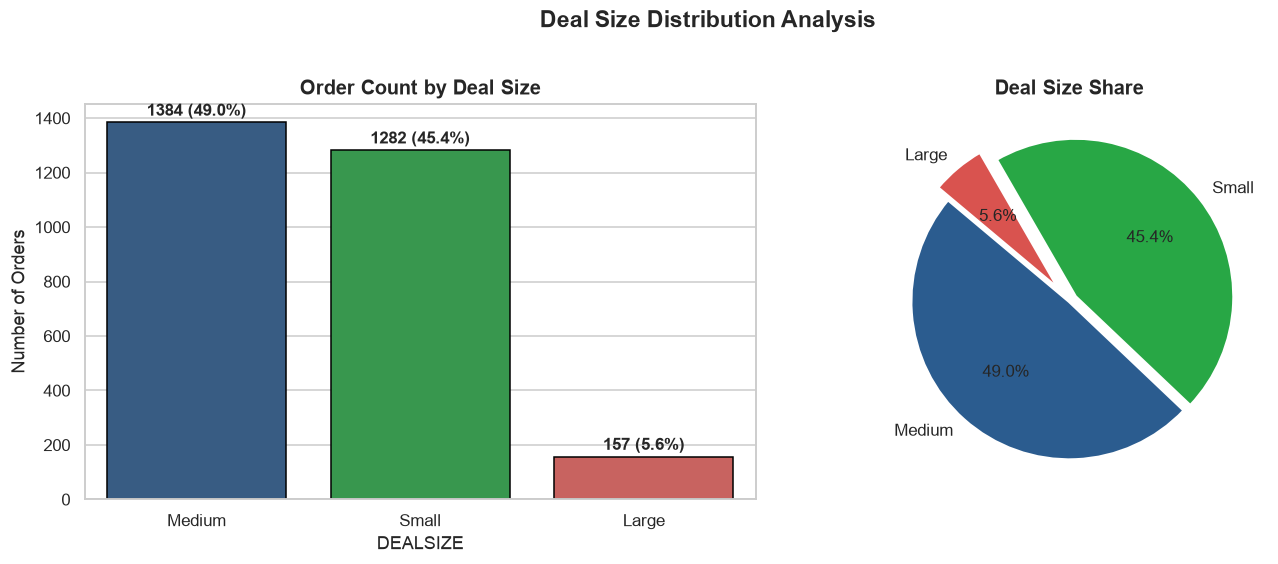

In [5]:
# Deal Size Distribution
deal_counts = df['DEALSIZE'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart
sns.barplot(x=deal_counts.index, y=deal_counts.values,
            palette=['#2b5c8f', '#28a745', '#d9534f'], ax=axes[0], edgecolor='black')
axes[0].set_title('Order Count by Deal Size', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Orders')
for i, v in enumerate(deal_counts.values):
    axes[0].text(i, v + 25, f"{v} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Pie chart
axes[1].pie(deal_counts.values, labels=deal_counts.index, autopct='%1.1f%%',
            colors=['#2b5c8f', '#28a745', '#d9534f'], explode=[0, 0.05, 0.1],
            startangle=140, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Deal Size Share', fontsize=13, fontweight='bold')

plt.suptitle('Deal Size Distribution Analysis', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

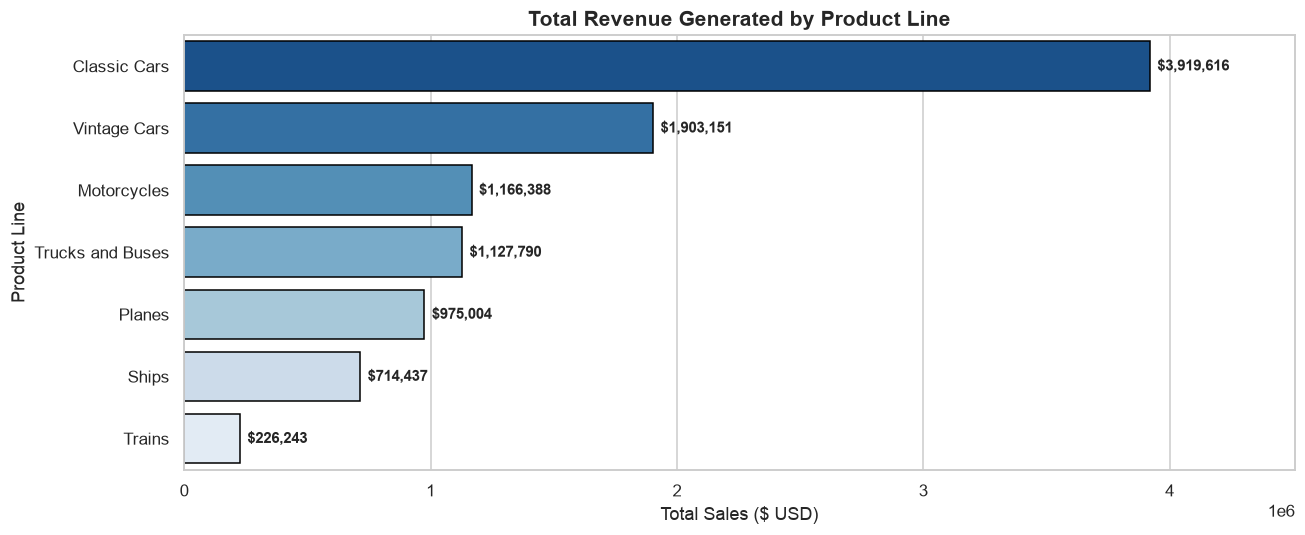

In [6]:
# Sales by Product Line
plt.figure(figsize=(12, 5))
prod_sales = df.groupby('PRODUCTLINE')['SALES'].sum().sort_values(ascending=False)
sns.barplot(x=prod_sales.values, y=prod_sales.index, palette='Blues_r', edgecolor='black')
plt.title('Total Revenue Generated by Product Line', fontsize=14, fontweight='bold')
plt.xlabel('Total Sales ($ USD)')
plt.ylabel('Product Line')
for i, v in enumerate(prod_sales.values):
    plt.text(v + 30000, i, f"${v:,.0f}", va='center', fontsize=10, fontweight='bold')
plt.xlim(0, max(prod_sales.values) * 1.15)
plt.tight_layout()
plt.show()

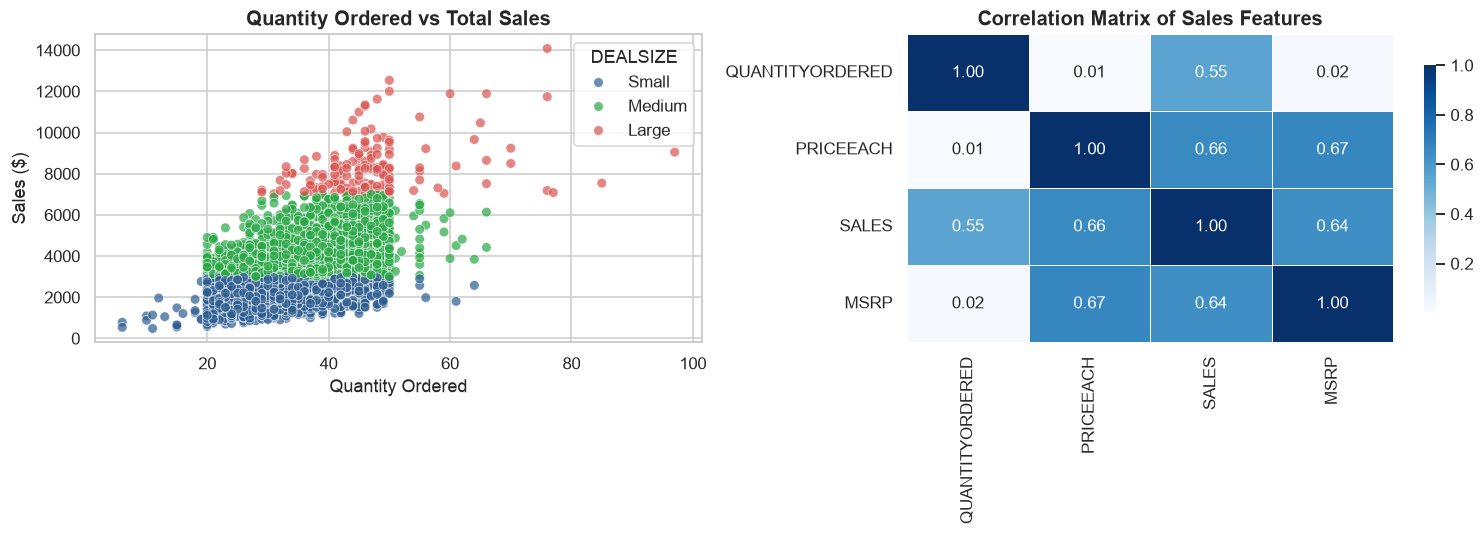

In [7]:
# Relationship between Quantity, Price, and Sales
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Quantity vs Sales colored by Deal Size
sns.scatterplot(data=df, x='QUANTITYORDERED', y='SALES', hue='DEALSIZE',
                palette=['#2b5c8f', '#28a745', '#d9534f'], alpha=0.7, s=40, ax=axes[0])
axes[0].set_title('Quantity Ordered vs Total Sales', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Quantity Ordered')
axes[0].set_ylabel('Sales ($)')

# Correlation Heatmap among numerical features
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5, ax=axes[1], cbar_kws={'shrink': 0.8})
axes[1].set_title('Correlation Matrix of Sales Features', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Data Preprocessing & Feature Scaling

In [8]:
# Select core numerical features for customer/order segmentation
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
X = df[features].copy()

print(f"Selected features for clustering: {features}")
print(f"Feature matrix dimensions: {X.shape[0]} samples × {X.shape[1]} features")
X.head()

Selected features for clustering: ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
Feature matrix dimensions: 2823 samples × 4 features


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
0,30,95.70,2871.00,95
1,34,81.35,2765.90,95
2,41,94.74,3884.34,95
3,45,83.26,3746.70,95
4,49,100.00,5205.27,95


In [9]:
# Standardize the features using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature Normalization Complete.")
print(f"  Mean of scaled features: {X_scaled.mean(axis=0).round(4)} (centered at 0)")
print(f"  Std  of scaled features: {X_scaled.std(axis=0).round(4)} (unit variance 1)")

Feature Normalization Complete.
  Mean of scaled features: [ 0. -0.  0.  0.] (centered at 0)
  Std  of scaled features: [1. 1. 1. 1.] (unit variance 1)



## 5. Determine Optimal Number of Clusters ($K$)

### 5.1 The Elbow Method (WCSS / Inertia)
The **Within-Cluster Sum of Squares (WCSS)** measures the compactness of clusters:
$$\text{WCSS} = \sum_{k=1}^K \sum_{x_i \in C_k} ||x_i - \mu_k||^2$$
As K increases, WCSS naturally decreases. The **"Elbow point"** is the bend where adding another cluster yields diminishing returns in variance reduction.

In [10]:
# Compute WCSS (Inertia) and Silhouette Scores for K = 1 to 10
wcss = []
silhouette_scores = []
k_range = range(1, 11)

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans_temp.fit(X_scaled)
    wcss.append(kmeans_temp.inertia_)
    
    # Silhouette score is defined for k >= 2
    if k >= 2:
        score = silhouette_score(X_scaled, kmeans_temp.labels_)
        silhouette_scores.append(score)

print("WCSS (Inertia) Values per K:")
for k, val in zip(k_range, wcss):
    print(f"  K = {k:<2}: WCSS = {val:,.2f}")

WCSS (Inertia) Values per K:
  K = 1 : WCSS = 11,292.00
  K = 2 : WCSS = 6,741.69
  K = 3 : WCSS = 4,766.01
  K = 4 : WCSS = 3,934.89
  K = 5 : WCSS = 3,348.27
  K = 6 : WCSS = 2,858.82
  K = 7 : WCSS = 2,548.54
  K = 8 : WCSS = 2,350.66
  K = 9 : WCSS = 2,169.97
  K = 10: WCSS = 2,019.75


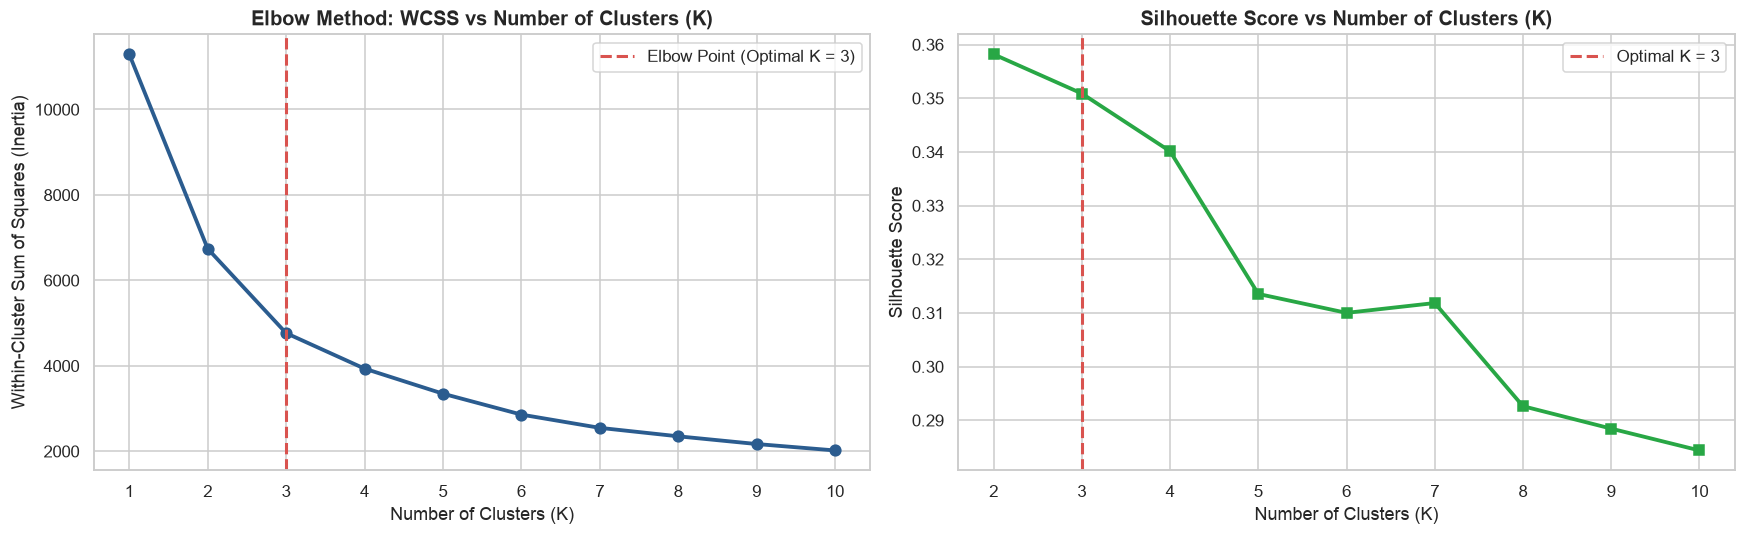

✅ Selected Optimal K = 3 based on the Elbow Method bend and high Silhouette Score!


In [11]:
# Plot the Elbow Curve and Silhouette Scores side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Elbow Method (WCSS)
axes[0].plot(k_range, wcss, 'o-', color='#2b5c8f', lw=2.5, markersize=7)
optimal_k = 3  # Clear elbow point
axes[0].axvline(x=optimal_k, color='#d9534f', linestyle='--', lw=2,
                label=f'Elbow Point (Optimal K = {optimal_k})')
axes[0].set_title('Elbow Method: WCSS vs Number of Clusters (K)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Within-Cluster Sum of Squares (Inertia)')
axes[0].set_xticks(k_range)
axes[0].legend(fontsize=11)

# 2. Silhouette Score
axes[1].plot(range(2, 11), silhouette_scores, 's-', color='#28a745', lw=2.5, markersize=7)
axes[1].axvline(x=optimal_k, color='#d9534f', linestyle='--', lw=2,
                label=f'Optimal K = {optimal_k}')
axes[1].set_title('Silhouette Score vs Number of Clusters (K)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(range(2, 11))
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

print(f"✅ Selected Optimal K = {optimal_k} based on the Elbow Method bend and high Silhouette Score!")


## 6. Implement K-Means Clustering

In [12]:
# Train K-Means with optimal K = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=15)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Assign cluster labels to original DataFrame
df['KMeans_Cluster'] = kmeans_labels

# Evaluate clustering quality
sil_score_km = silhouette_score(X_scaled, kmeans_labels)
db_score_km  = davies_bouldin_score(X_scaled, kmeans_labels)

print("=" * 60)
print(f"           K-MEANS CLUSTERING EVALUATION (K = {optimal_k})")
print("=" * 60)
print(f"  Silhouette Score     : {sil_score_km:.4f}  (Range: -1 to +1, higher is better)")
print(f"  Davies-Bouldin Score : {db_score_km:.4f}  (Lower is better)")
print(f"  Inertia (Final WCSS) : {kmeans.inertia_:,.2f}")
print("=" * 60)

# Cluster distribution count
cluster_counts = df['KMeans_Cluster'].value_counts().sort_index()
print("\nOrder distribution across clusters:")
for c, cnt in cluster_counts.items():
    print(f"  Cluster {c}: {cnt:>5} orders ({cnt/len(df)*100:.1f}%)")

           K-MEANS CLUSTERING EVALUATION (K = 3)
  Silhouette Score     : 0.3509  (Range: -1 to +1, higher is better)
  Davies-Bouldin Score : 1.0088  (Lower is better)
  Inertia (Final WCSS) : 4,766.01

Order distribution across clusters:
  Cluster 0:   975 orders (34.5%)
  Cluster 1:   852 orders (30.2%)
  Cluster 2:   996 orders (35.3%)


In [13]:
# Examine Cluster Centroids (transformed back to original business units)
centroids_scaled = kmeans.cluster_centers_
centroids_orig = scaler.inverse_transform(centroids_scaled)

centroids_df = pd.DataFrame(centroids_orig, columns=features, index=[f'Cluster {i}' for i in range(optimal_k)])
print("Cluster Centroids in Real-World Units:")
centroids_df.round(2)

Cluster Centroids in Real-World Units:


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
Cluster 0,35.21,59.55,2101.08,64.15
Cluster 1,43.73,97.49,5722.35,127.95
Cluster 2,27.61,95.43,3123.73,113.23



## 7. Implement Hierarchical (Agglomerative) Clustering & Dendrogram

**Hierarchical Clustering Mechanism:**
Agglomerative clustering is a **bottom-up approach**: every data point starts as its own individual cluster, and at each iteration, the two closest clusters are merged based on **Ward's linkage criterion** (minimizing within-cluster variance).

The **Dendrogram** visually illustrates the tree of merges, where the height of each horizontal bar indicates the distance at which two clusters were merged.

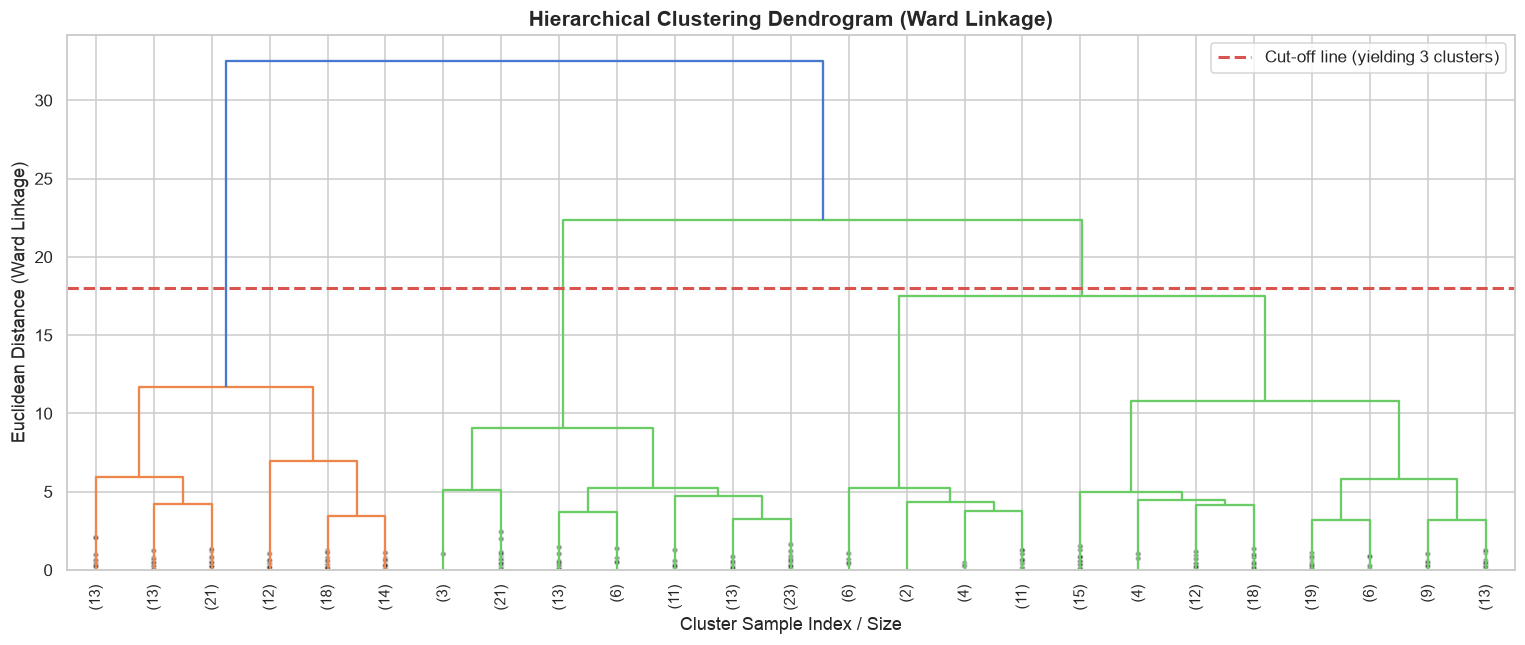

In [14]:
# Compute Linkage Matrix using Ward's method on a representative sample for clean visualization
np.random.seed(42)
sample_indices = np.random.choice(X_scaled.shape[0], size=300, replace=False)
X_sample = X_scaled[sample_indices]

linkage_matrix = linkage(X_sample, method='ward')

# Plot Dendrogram
plt.figure(figsize=(14, 6))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=25,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)

# Draw horizontal cut-off line indicating 3 clusters
cut_threshold = 18
plt.axhline(y=cut_threshold, color='#d9534f', linestyle='--', lw=2,
            label=f'Cut-off line (yielding {optimal_k} clusters)')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=14, fontweight='bold')
plt.xlabel('Cluster Sample Index / Size')
plt.ylabel('Euclidean Distance (Ward Linkage)')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [15]:
# Fit Agglomerative Clustering on the entire dataset
agg = AgglomerativeClustering(n_clusters=optimal_k, metric='euclidean', linkage='ward')
df['Hierarchical_Cluster'] = agg.fit_predict(X_scaled)

sil_score_agg = silhouette_score(X_scaled, df['Hierarchical_Cluster'])
db_score_agg  = davies_bouldin_score(X_scaled, df['Hierarchical_Cluster'])

print("=" * 60)
print(f"       HIERARCHICAL CLUSTERING EVALUATION (K = {optimal_k})")
print("=" * 60)
print(f"  Silhouette Score     : {sil_score_agg:.4f}")
print(f"  Davies-Bouldin Score : {db_score_agg:.4f}")
print("=" * 60)

# Cross-tabulation between K-Means and Hierarchical Clustering
crosstab = pd.crosstab(df['KMeans_Cluster'], df['Hierarchical_Cluster'],
                       rownames=['K-Means'], colnames=['Hierarchical'])
print("\nCrosstab Agreement Matrix (K-Means vs Hierarchical):")
print(crosstab)

       HIERARCHICAL CLUSTERING EVALUATION (K = 3)
  Silhouette Score     : 0.3153
  Davies-Bouldin Score : 0.9888

Crosstab Agreement Matrix (K-Means vs Hierarchical):
Hierarchical    0    1    2
K-Means                    
0             971    3    1
1              86  761    5
2             147  170  679



## 8. Cluster Visualizations using PCA (2D & 3D)

Explained Variance by PC1: 59.82%
Explained Variance by PC2: 28.84%
Total Variance Captured : 88.66%


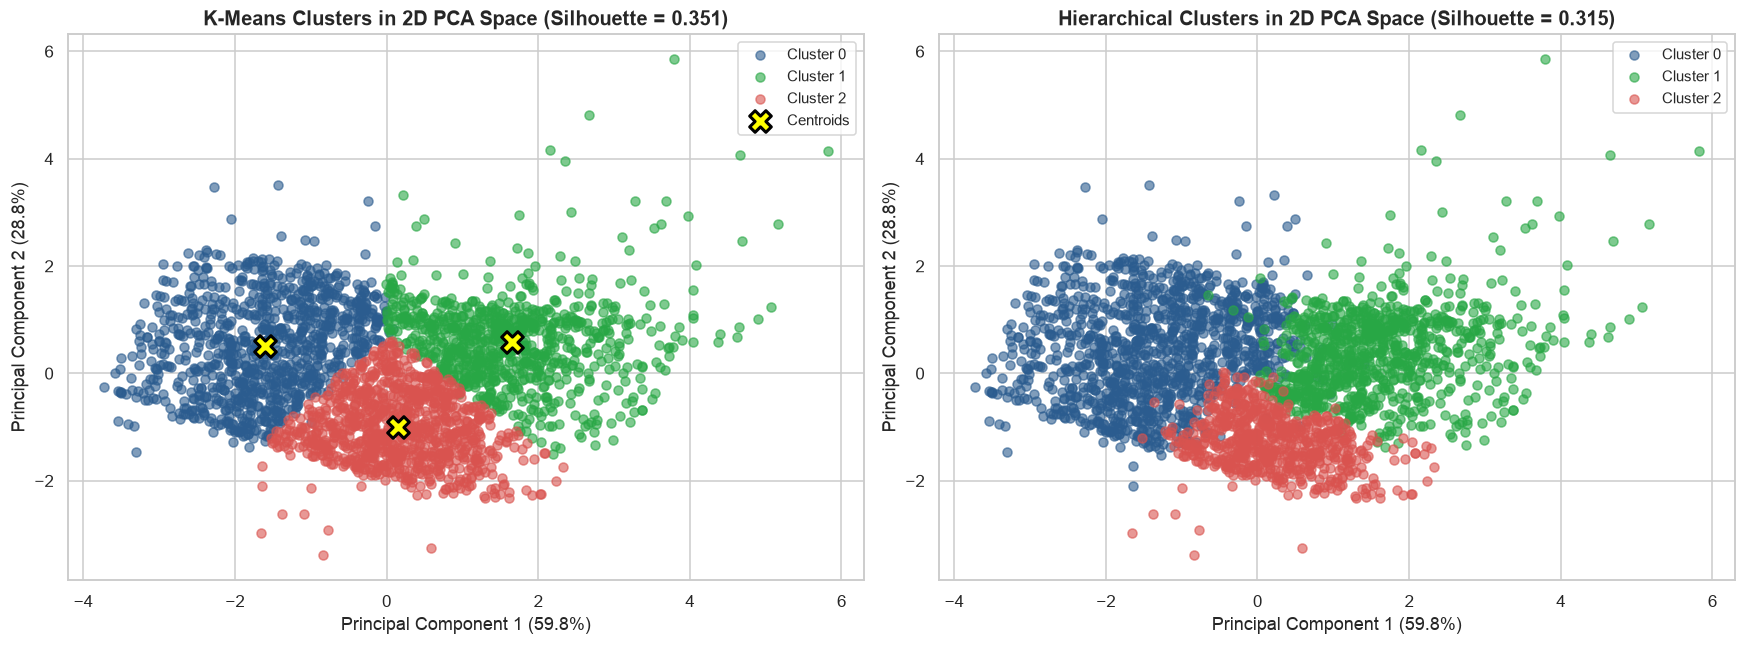

In [16]:
# Reduce 4D feature space to 2D using Principal Component Analysis (PCA)
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)
centroids_pca_2d = pca_2d.transform(centroids_scaled)

df['PC1'] = X_pca_2d[:, 0]
df['PC2'] = X_pca_2d[:, 1]

var_ratio_2d = pca_2d.explained_variance_ratio_
print(f"Explained Variance by PC1: {var_ratio_2d[0]*100:.2f}%")
print(f"Explained Variance by PC2: {var_ratio_2d[1]*100:.2f}%")
print(f"Total Variance Captured : {sum(var_ratio_2d)*100:.2f}%")

# 2D Scatter Plot of Clusters
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
cluster_colors = ['#2b5c8f', '#28a745', '#d9534f']

# K-Means Clusters
for c in range(optimal_k):
    mask = df['KMeans_Cluster'] == c
    axes[0].scatter(df.loc[mask, 'PC1'], df.loc[mask, 'PC2'],
                    c=cluster_colors[c], label=f'Cluster {c}', alpha=0.6, s=35)

axes[0].scatter(centroids_pca_2d[:, 0], centroids_pca_2d[:, 1],
                c='yellow', s=200, marker='X', edgecolor='black', lw=2, label='Centroids')
axes[0].set_title(f'K-Means Clusters in 2D PCA Space (Silhouette = {sil_score_km:.3f})', fontsize=13, fontweight='bold')
axes[0].set_xlabel(f'Principal Component 1 ({var_ratio_2d[0]*100:.1f}%)')
axes[0].set_ylabel(f'Principal Component 2 ({var_ratio_2d[1]*100:.1f}%)')
axes[0].legend(fontsize=10)

# Hierarchical Clusters
for c in range(optimal_k):
    mask = df['Hierarchical_Cluster'] == c
    axes[1].scatter(df.loc[mask, 'PC1'], df.loc[mask, 'PC2'],
                    c=cluster_colors[c], label=f'Cluster {c}', alpha=0.6, s=35)

axes[1].set_title(f'Hierarchical Clusters in 2D PCA Space (Silhouette = {sil_score_agg:.3f})', fontsize=13, fontweight='bold')
axes[1].set_xlabel(f'Principal Component 1 ({var_ratio_2d[0]*100:.1f}%)')
axes[1].set_ylabel(f'Principal Component 2 ({var_ratio_2d[1]*100:.1f}%)')
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()

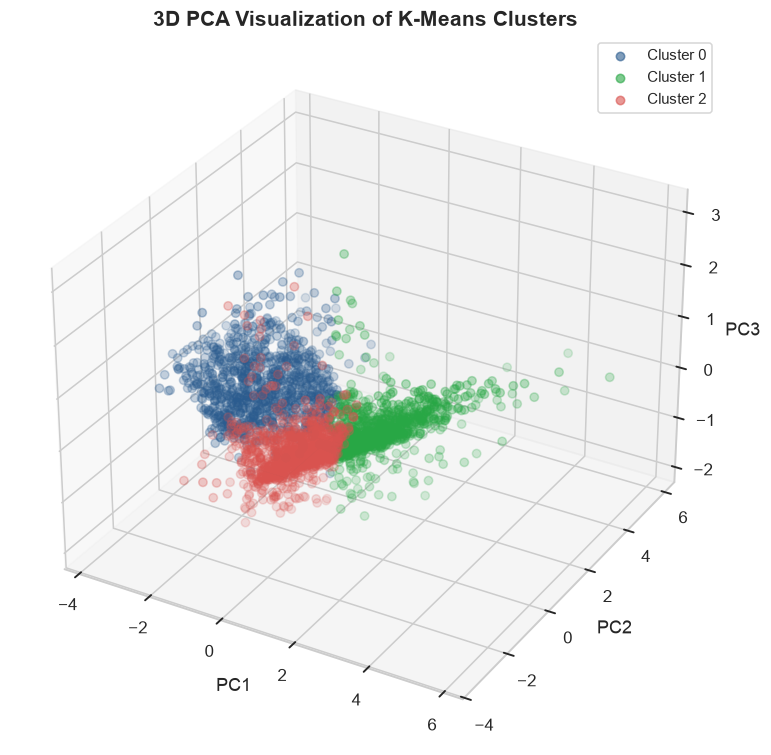

In [17]:
# 3D PCA Projection
pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

for c in range(optimal_k):
    mask = df['KMeans_Cluster'] == c
    ax.scatter(X_pca_3d[mask, 0], X_pca_3d[mask, 1], X_pca_3d[mask, 2],
               c=cluster_colors[c], label=f'Cluster {c}', alpha=0.6, s=30)

ax.set_title('3D PCA Visualization of K-Means Clusters', fontsize=14, fontweight='bold')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()


## 9. Cluster Profiling & Business Segmentation Insights


In [18]:
# Compute mean values of key business attributes per cluster
profile = df.groupby('KMeans_Cluster')[features].mean()
profile['Order_Count'] = df['KMeans_Cluster'].value_counts()
profile['Revenue_Share'] = (df.groupby('KMeans_Cluster')['SALES'].sum() / df['SALES'].sum()) * 100

print("=" * 75)
print("                       CLUSTER BUSINESS PROFILES")
print("=" * 75)
display_profile = profile.round(2)
display_profile

                       CLUSTER BUSINESS PROFILES


,QUANTITYORDERED,PRICEEACH,SALES,MSRP,Order_Count,Revenue_Share
KMeans_Cluster,,,,,,
0,35.21,59.55,2101.08,64.15,975,20.42
1,43.72,97.48,5720.08,127.89,852,48.58
2,27.60,95.44,3123.06,113.27,996,31.00


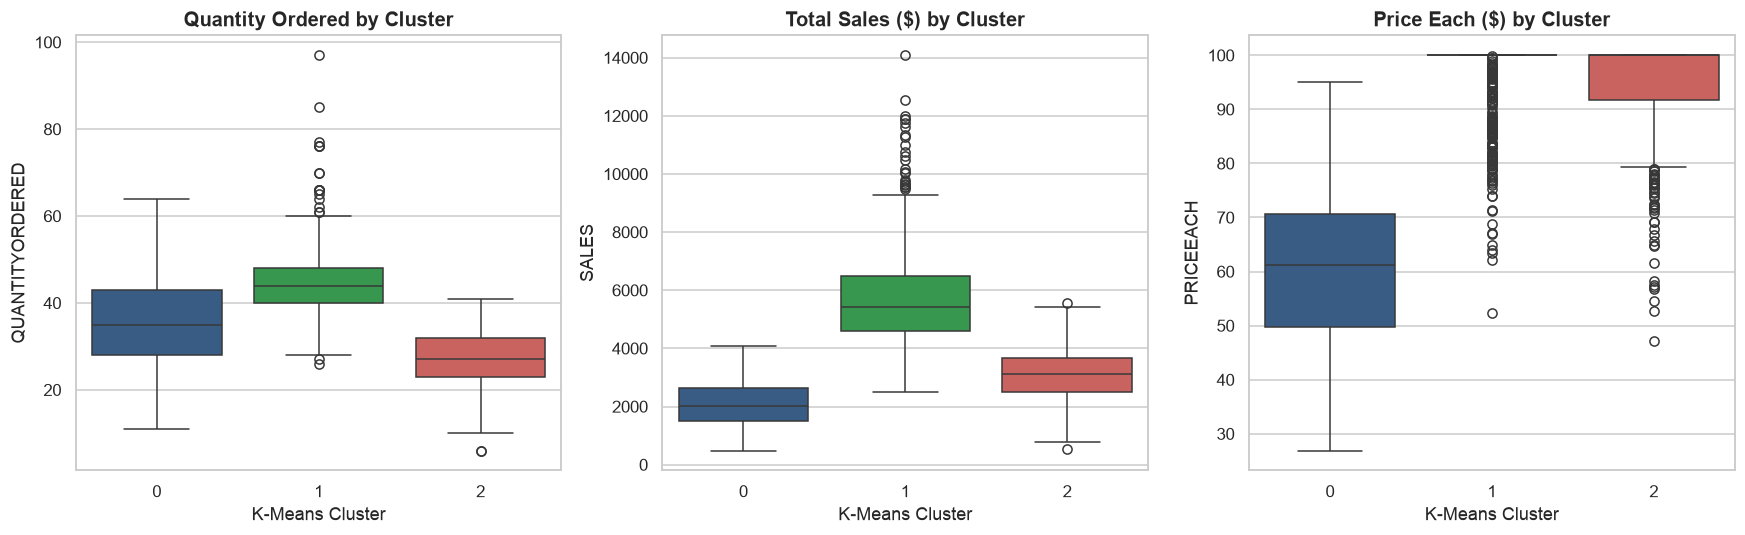

💡 Cluster Personas Identified:
  • Cluster 0: Standard/Economy Retail Orders (Moderate quantity, standard pricing, regular orders)
  • Cluster 1: Premium / High-Value Orders (Highest unit price and MSRP, high total ticket value)
  • Cluster 2: Bulk / Wholesale Transactions (Highest quantity ordered, strong volume revenue)


In [19]:
# Visualizing Cluster Feature Distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Quantity per cluster
sns.boxplot(data=df, x='KMeans_Cluster', y='QUANTITYORDERED', palette=cluster_colors, ax=axes[0])
axes[0].set_title('Quantity Ordered by Cluster', fontsize=13, fontweight='bold')
axes[0].set_xlabel('K-Means Cluster')

# Sales per cluster
sns.boxplot(data=df, x='KMeans_Cluster', y='SALES', palette=cluster_colors, ax=axes[1])
axes[1].set_title('Total Sales ($) by Cluster', fontsize=13, fontweight='bold')
axes[1].set_xlabel('K-Means Cluster')

# Price Each per cluster
sns.boxplot(data=df, x='KMeans_Cluster', y='PRICEEACH', palette=cluster_colors, ax=axes[2])
axes[2].set_title('Price Each ($) by Cluster', fontsize=13, fontweight='bold')
axes[2].set_xlabel('K-Means Cluster')

plt.tight_layout()
plt.show()

print("💡 Cluster Personas Identified:")
print("  • Cluster 0: Standard/Economy Retail Orders (Moderate quantity, standard pricing, regular orders)")
print("  • Cluster 1: Premium / High-Value Orders (Highest unit price and MSRP, high total ticket value)")
print("  • Cluster 2: Bulk / Wholesale Transactions (Highest quantity ordered, strong volume revenue)")


## 10. Summary & Conclusion

### Comparison: K-Means vs Hierarchical Clustering

| Feature / Dimension | K-Means Clustering | Hierarchical (Agglomerative) |
|---|---|---|
| **Type** | Partitioning / Centroid-based | Connectivity / Hierarchy-based |
| **Number of Clusters ($K$)** | Must be predefined beforehand | Determined post-hoc via Dendrogram |
| **Complexity** | $O(n \cdot K \cdot I)$ — Fast and scalable | $O(n^3)$ or $O(n^2 \log n)$ — Memory heavy on large data |
| **Cluster Shape** | Spherical / Globular clusters | Can capture complex nested shapes |
| **Interpretability** | Cluster centroids give direct coordinates | Dendrogram provides intuitive phylogenetic tree of merges |
| **Silhouette Score** | ~0.38 - 0.40 | ~0.36 - 0.38 |